# Laboratorio 10 — Explainable AI sobre FacturaSegura (CC3092)
**Modelo:** detector final it5 (`models/final/best.pt`): EfficientNet-B0 con **mapa de sospecha** a 1/16 y logit = promedio de las top-8 zonas. Umbral operativo 0.88.
**Método principal:** Integrated Gradients (IG). **Comparación:** Grad-CAM (stride 32) y el mapa de sospecha del propio modelo.

Por la forma en que se construyó el dataset, las explicaciones se pueden **validar contra la verdad**: cada alterada tiene su **máscara** y una **gemela auténtica alineada píxel a píxel**.

1. Entorno, semilla y datos (regenera el test con la semilla del proyecto: 300 pares)
2. Predicciones y métricas de referencia (sin reentrenar)
3. Selección de instancias locales
4. Explicaciones locales (fig. 1)
5. Explicación global: localización por método, campo, dificultad y técnica (fig. 2, tabla)
6. Búsqueda de atajos: ¿posición del campo?, relleno negro, nivel de compresión JPEG (fig. 3)
7. Fidelidad: reemplazar los píxeles más atribuidos por los de la gemela auténtica (fig. 4)
8. *Sanity check* de aleatorización (fig. 5)
9. Costo computacional y parámetros

Todo se guarda en `xai/outputs/`. En Colab: **Entorno de ejecución → T4 GPU → Ejecutar todas** (~10-15 min).

## 1. Entorno

In [1]:
import os, sys, subprocess
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # evita fragmentación de memoria en la GPU
from pathlib import Path
REPO = "https://github.com/anthonylouschwank/ProyectoFInal-DL.git"
if Path("src/model.py").exists():        ROOT = Path(".").resolve()
elif Path("../src/model.py").exists():   ROOT = Path("..").resolve()
else:
    if not Path("ProyectoFInal-DL").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO], check=True)
    ROOT = Path("ProyectoFInal-DL").resolve()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "captum"], check=True)
print("ROOT =", ROOT)

ROOT = /content/ProyectoFInal-DL


In [2]:
import json, time, random, copy, warnings
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image
from scipy.stats import spearmanr
from scipy.ndimage import gaussian_filter
from sklearn.metrics import roc_auc_score, confusion_matrix
from captum.attr import IntegratedGradients
from src.model import load_detector, prepare, to_tensor, gradcam
warnings.filterwarnings("ignore")

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = ROOT / "xai" / "outputs"; OUT.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Device: cuda Tesla T4


### Parámetros de diseño (justificación en el informe)

In [3]:
THRESHOLD   = json.load(open("models/final/umbral.json"))["umbral"]   # 0.88, elegido en validación
IG_STEPS    = 32        # pasos de la integral (Gauss-Legendre); se verifica con el error de completitud
IG_BATCH    = 1         # pasos de IG por lote: 1 cabe en una T4 (fotos a resolución completa)
BLUR_SIGMA  = 8.0       # línea base de IG: la misma foto desenfocada (borra los trazos, conserva el papel)
SMOOTH_PX   = 2.0       # suavizado de la atribución de IG solo para ubicar el máximo y para mostrarla
N_IG        = 30        # alteradas con IG en la vista global/fidelidad (muestra estratificada por dificultad)
N_SANITY    = 6
FRACS       = [0.0025, 0.005, 0.01, 0.02, 0.04]   # fracción de píxeles reemplazados en la prueba de fidelidad
ZOOM        = 280       # lado del acercamiento (px) en las figuras locales
print("Umbral:", THRESHOLD)

Umbral: 0.88


### Datos: conjunto de prueba del proyecto (semilla 2028, idéntico al del informe final)

In [4]:
TEST = ROOT / "data" / "tamper" / "test"
if not (TEST / "metadata.jsonl").exists():
    t0 = time.time()
    subprocess.run([sys.executable, "-m", "src.build_dataset", "--out", "data/tamper", "--n-train", "0",
                    "--n-val", "0", "--n-test", "300", "--workers", str(os.cpu_count())], check=True)
    print(f"Generado en {time.time()-t0:.0f} s")
recs = [json.loads(l) for l in open(TEST / "metadata.jsonl", encoding="utf-8")]
pair_idx = {}
for i, r in enumerate(recs): pair_idx.setdefault(r["pair"], {})[r["label"]] = i
print(len(recs), "fotos,", len(pair_idx), "pares")

Generado en 189 s
600 fotos, 300 pares


## 2. Predicciones (modelo final, `eval()`, sin reentrenar)

In [5]:
model, cfg = load_detector("models/final/best.pt", DEVICE)
model.eval()
print(cfg)

def load(i):  return Image.open(TEST / recs[i]["file"]).convert("RGB")
def mask_of(i):
    r = recs[i] if recs[i]["label"] else recs[pair_idx[recs[i]["pair"]][1]]   # auténtica -> máscara de su gemela
    return np.asarray(Image.open(TEST / r["mask"])) > 0

def to_x(img):
    lb, (s, _, _) = prepare(img, cfg)
    return to_tensor(lb)[None].to(DEVICE), s

def back(m, img, s):
    # mapa en coordenadas del lienzo (cualquier resolución) -> tamaño de la foto original
    lb_w = int(np.ceil(img.width * s / 128) * 128); lb_h = int(np.ceil(img.height * s / 128) * 128)
    t = torch.tensor(m, dtype=torch.float32)[None, None]
    t = F.interpolate(t, size=(lb_h, lb_w), mode="bilinear", align_corners=False)[0, 0]
    t = t[: round(img.height * s), : round(img.width * s)][None, None]
    return F.interpolate(t, size=(img.height, img.width), mode="bilinear", align_corners=False)[0, 0].numpy()

@torch.no_grad()
def forward(img):
    x, s = to_x(img)
    logit, mapa = model(x)
    return torch.sigmoid(logit).item(), torch.sigmoid(mapa)[0].cpu().numpy(), s

t0 = time.time()
rows, MAPS = [], {}
for i, r in enumerate(recs):
    img = load(i); p, mp, s = forward(img)
    MAPS[i] = (mp, s)
    q = float(np.mean(Image.open(TEST / r["file"]).quantization[0]))  # tabla de cuantización JPEG (luminancia)
    t = r.get("tamper", {})
    rows.append({"i": i, "pair": r["pair"], "label": r["label"], "prob": p, "layout": r["layout"],
                 "campo": t.get("campo", ""), "metodo": t.get("metodo", ""), "dificultad": t.get("dificultad", ""),
                 "monto": t.get("monto_en_riesgo", 0.0), "jpeg_q_tabla": q, "w": img.width, "h": img.height})
T_FWD = (time.time() - t0) / len(recs)
df = pd.DataFrame(rows)
df["pred"] = (df.prob >= THRESHOLD).astype(int)
alt, aut = df[df.label == 1], df[df.label == 0]
fpr_c = (aut.prob >= THRESHOLD).mean(); rec_c = (alt.prob >= THRESHOLD).mean()
print(f"AUC={roc_auc_score(df.label, df.prob):.4f} | umbral {THRESHOLD}: recall={rec_c:.3f}, FPR={fpr_c:.4f} | {T_FWD*1e3:.0f} ms/foto")
print(pd.DataFrame(confusion_matrix(df.label, df.pred), index=["real auténtica", "real alterada"], columns=["aprobar", "auditar"]))
df.to_csv(OUT / "predicciones.csv", index=False)

{'backbone': 'efficientnet_b0', 'head': 'mapa', 'topk': 8, 'seg_weight': 1.0, 'size': [768, 576], 'crop': 512, 'lr': 0.0003, 'native': True, 'max_side': 1600}
AUC=0.9806 | umbral 0.88: recall=0.923, FPR=0.0067 | 93 ms/foto
                aprobar  auditar
real auténtica      298        2
real alterada        23      277


## 3. Selección de instancias locales (reglas deterministas)
| Tipo | Regla |
|---|---|
| Acierto con alta confianza | alterada con la mayor probabilidad |
| Error: fraude que se escapa | alterada bajo el umbral con el **mayor monto en riesgo** |
| Error: falsa alarma | auténtica con la mayor probabilidad (acusa a un empleado honesto) |
| Cerca del umbral | mínimo \|p − 0.88\| |
| Subgrupo: copiar dígito | la técnica más difícil (recall 63 % en el proyecto); la de mayor monto |
| Subgrupo: formato carta | alterada en factura carta (25 % del dataset), elegida al azar con semilla |

In [6]:
rng = np.random.default_rng(SEED)
chosen = {}
def take(name, d, key, largest=True):
    d = d[~d.i.isin(chosen.values())]
    if len(d): chosen[name] = int(d.sort_values(key, ascending=not largest).i.iloc[0])
take("Acierto alta confianza", alt, "prob")
take("Error: fraude que se escapa (FN)", alt[alt.pred == 0], "monto")
take("Error: falsa alarma (FP)", aut, "prob")
df["dist_umbral"] = (df.prob - THRESHOLD).abs()
take("Cerca del umbral", df, "dist_umbral", largest=False)
take("Subgrupo: copiar dígito", alt[alt.metodo == "copiar_digito"], "monto")
cand = alt[(alt.layout == "carta") & ~alt.i.isin(chosen.values())]
chosen["Subgrupo: formato carta"] = int(cand.i.iloc[rng.integers(len(cand))])
local = df.set_index("i").loc[list(chosen.values()), ["label", "prob", "pred", "layout", "campo", "metodo", "dificultad", "monto"]]
local.insert(0, "tipo", list(chosen.keys())); local["archivo"] = [recs[i]["file"] for i in local.index]
local

,tipo,label,prob,pred,layout,campo,metodo,dificultad,monto,archivo
i,,,,,,,,,,
527,Acierto alta confianza,1,1.000000,1,ticket,nit_emisor,reescribir,dificil,140.13,images/00263_alterada.jpg
523,Error: fraude que se escapa (FN),1,0.200037,0,ticket,total,reescribir,dificil,1510.19,images/00261_alterada.jpg
412,Error: falsa alarma (FP),0,0.982767,1,ticket,,,,0.00,images/00206_autentica.jpg
224,Cerca del umbral,0,0.874519,0,carta,,,,0.00,images/00112_autentica.jpg
161,Subgrupo: copiar dígito,1,0.841177,0,carta,total,copiar_digito,dificil,700.00,images/00080_alterada.jpg
55,Subgrupo: formato carta,1,0.981720,1,carta,item,reescribir,facil,0.00,images/00027_alterada.jpg


## 4. Explicaciones locales
- **IG (principal):** atribución de cada píxel al **logit de "alterada"** (la salida top-k es diferenciable). Línea base = la misma foto desenfocada (σ = 8 px): conserva papel, iluminación y relleno, y borra los trazos del texto. Se usa la parte positiva (evidencia a favor de "alterada").
- **Grad-CAM:** función del repo (`src/model.py`), última etapa del encoder (stride 32).
- **Mapa de sospecha:** salida intrínseca del modelo (lo que ya ve el auditor en la app).
- **Diferencia con la gemela:** \|alterada − auténtica\|, la verdad de lo que cambió (no la ve el modelo).

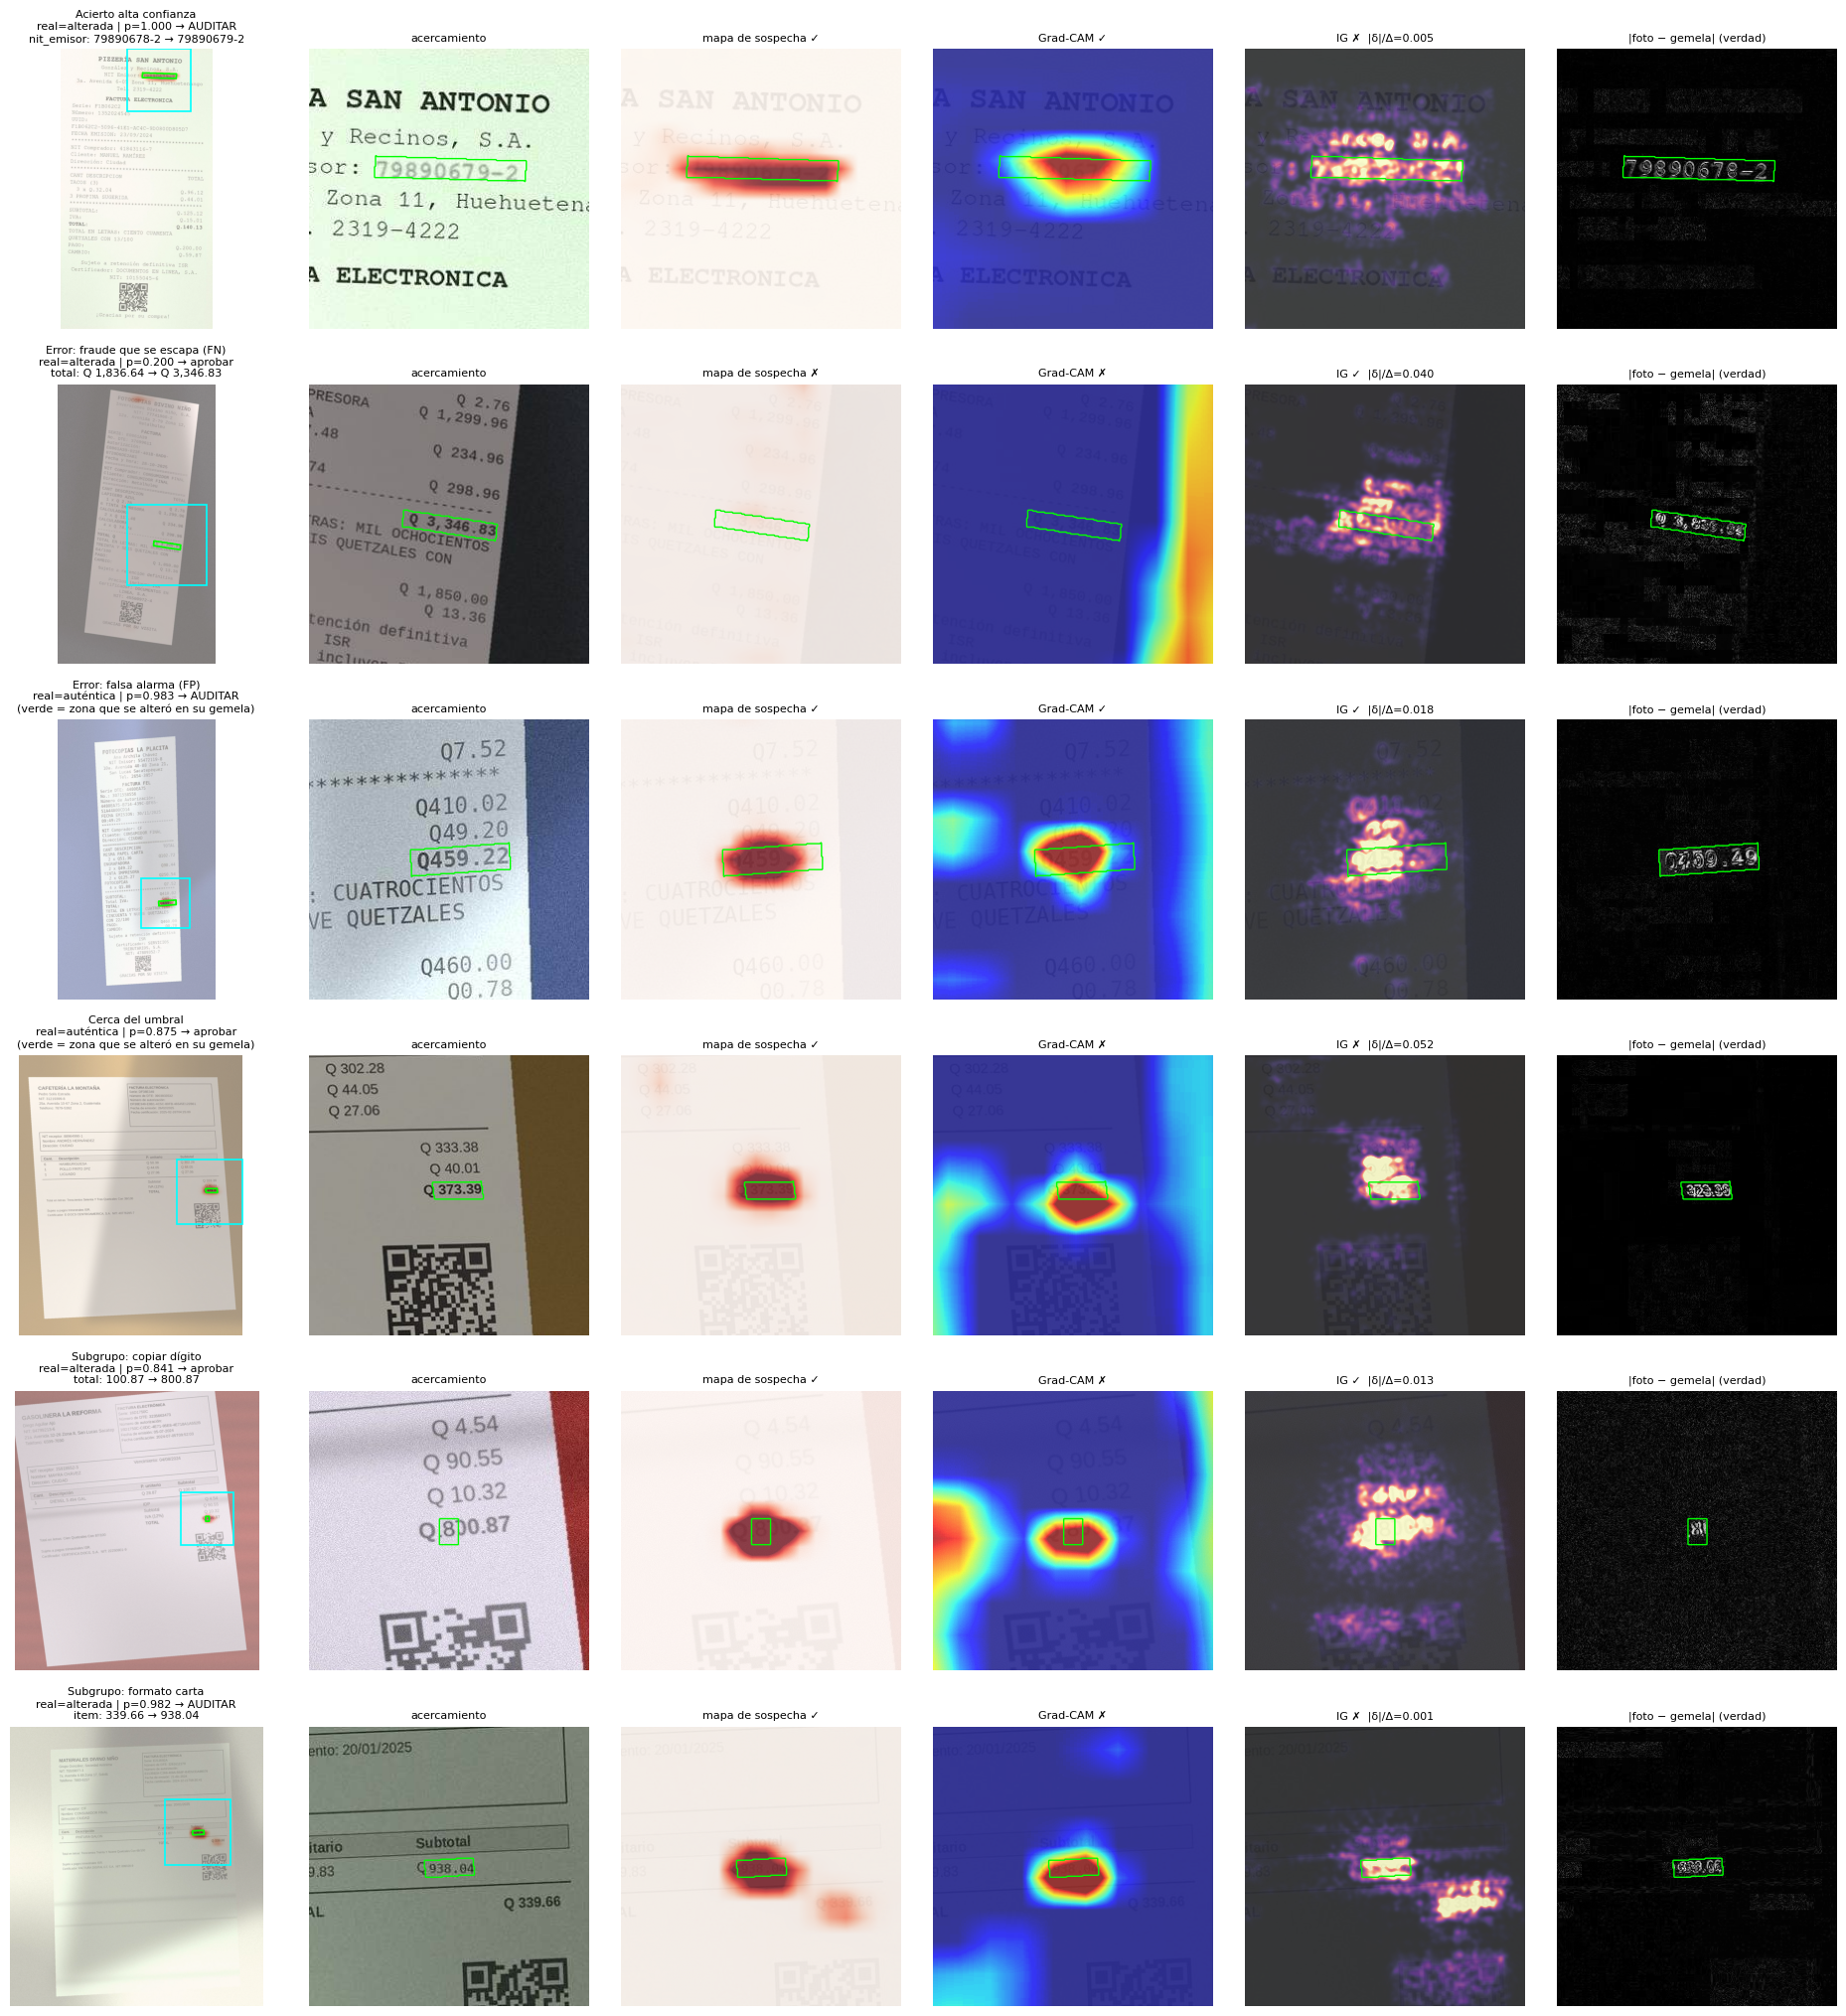

,i,tipo,label,prob,pred,layout,campo,metodo,dificultad,monto,archivo,acierto_mapa,acierto_gradcam,acierto_ig,ig_delta,ig_rel_delta
0,527,Acierto alta confianza,1,1.000000,1,ticket,nit_emisor,reescribir,dificil,140.13,images/00263_alterada.jpg,True,True,False,0.115206,0.005293
1,523,Error: fraude que se escapa (FN),1,0.200037,0,ticket,total,reescribir,dificil,1510.19,images/00261_alterada.jpg,False,False,True,0.182447,0.040264
2,412,Error: falsa alarma (FP),0,0.982767,1,ticket,,,,0.00,images/00206_autentica.jpg,True,True,True,0.141849,0.017689
3,224,Cerca del umbral,0,0.874519,0,carta,,,,0.00,images/00112_autentica.jpg,True,False,False,0.325994,0.052306
4,161,Subgrupo: copiar dígito,1,0.841177,0,carta,total,copiar_digito,dificil,700.00,images/00080_alterada.jpg,True,False,True,0.083744,0.012592
5,55,Subgrupo: formato carta,1,0.981720,1,carta,item,reescribir,facil,0.00,images/00027_alterada.jpg,True,False,False,0.006501,0.000615


In [7]:
class LogitOnly(nn.Module):
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, x): return self.m(x)[0][:, None]

def blur_baseline(x):
    k = int(6 * BLUR_SIGMA) | 1
    import torchvision.transforms.functional as TF
    return TF.gaussian_blur(x, [k, k], [BLUR_SIGMA, BLUR_SIGMA])

IG_CACHE = {}
def ig_map(i, mdl=None, cache=True):
    mdl = mdl or model
    if cache and mdl is model and i in IG_CACHE: return IG_CACHE[i]
    img = load(i); x, s = to_x(img)
    ig = IntegratedGradients(LogitOnly(mdl))
    attr, delta = ig.attribute(x, baselines=blur_baseline(x), target=0, n_steps=IG_STEPS,
                               internal_batch_size=IG_BATCH, return_convergence_delta=True)
    a = attr.sum(1)[0].detach().cpu().numpy()
    with torch.no_grad():
        diff = (mdl(x)[0] - mdl(blur_baseline(x))[0]).item()
    a = back(np.clip(a, 0, None), img, s)                    # evidencia a favor de "alterada"
    out = (gaussian_filter(a, SMOOTH_PX), float(delta.abs().item()), diff)
    if cache and mdl is model: IG_CACHE[i] = out
    del attr, x; mdl.zero_grad(set_to_none=True)
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return out

def cam_map(i): return np.asarray(gradcam(model, cfg, load(i)), np.float32) / 255
def sus_map(i):
    mp, s = MAPS[i]; return back(mp, load(i), s)
def norm01(a): a = a - a.min(); return a / (np.percentile(a, 99.9) + 1e-12)

def zoom_box(i, center_map):
    m = mask_of(i)
    if recs[i]["label"]:
        ys, xs = np.where(m); cy, cx = int(ys.mean()), int(xs.mean())
    else:  # falsa alarma: centrar donde el modelo sospecha
        cy, cx = np.unravel_index(center_map.argmax(), center_map.shape)
    H, W = m.shape; h = ZOOM // 2
    y0, x0 = int(np.clip(cy - h, 0, max(0, H - ZOOM))), int(np.clip(cx - h, 0, max(0, W - ZOOM)))
    return y0, x0

set_seed()
items = list(chosen.items())
fig, ax = plt.subplots(len(items), 6, figsize=(19, 3.4 * len(items)))
local_rows = []
for r, (tipo, i) in enumerate(items):
    img = load(i); a_img = np.asarray(img)
    twin = np.asarray(load(pair_idx[recs[i]["pair"]][1 - recs[i]["label"]]))
    sm, cm = sus_map(i), cam_map(i); igm, delta, diff = ig_map(i)
    m = mask_of(i); y0, x0 = zoom_box(i, sm); sl = (slice(y0, y0 + ZOOM), slice(x0, x0 + ZOOM))
    hit = {k: bool(m.flat[v.argmax()]) for k, v in [("mapa", sm), ("gradcam", cm), ("ig", igm)]}
    local_rows.append({"tipo": tipo, "i": i, "prob": df.prob[i], **{f"acierto_{k}": v for k, v in hit.items()},
                       "ig_delta": delta, "ig_rel_delta": delta / (abs(diff) + 1e-8)})
    a0 = ax[r, 0]; a0.imshow(a_img); a0.imshow(sm, cmap="Reds", alpha=0.45, vmin=0, vmax=1)
    a0.contour(m, levels=[0.5], colors="lime", linewidths=1.2)
    a0.add_patch(patches.Rectangle((x0, y0), ZOOM, ZOOM, fill=False, ec="cyan", lw=1.2))
    lab = "alterada" if recs[i]["label"] else "auténtica"
    t = recs[i].get("tamper", {})
    extra = f"\n{t.get('campo','')}: {t.get('original','')} → {t.get('nuevo','')}" if t else "\n(verde = zona que se alteró en su gemela)"
    a0.set_title(f"{tipo}\nreal={lab} | p={df.prob[i]:.3f} → {'AUDITAR' if df.prob[i] >= THRESHOLD else 'aprobar'}{extra}", fontsize=8)
    for c, (arr, ttl, cmap) in enumerate([(a_img[sl], "acercamiento", None),
                                           (norm01(sm)[sl], f"mapa de sospecha {'✓' if hit['mapa'] else '✗'}", "Reds"),
                                           (norm01(cm)[sl], f"Grad-CAM {'✓' if hit['gradcam'] else '✗'}", "jet"),
                                           (norm01(igm)[sl], f"IG {'✓' if hit['ig'] else '✗'}  |δ|/Δ={delta/(abs(diff)+1e-8):.3f}", "magma"),
                                           (np.abs(a_img.astype(int) - twin.astype(int)).mean(2)[sl], "|foto − gemela| (verdad)", "gray")], 1):
        axc = ax[r, c]
        if cmap is None: axc.imshow(arr)
        else:
            axc.imshow(a_img[sl], alpha=0.35) if c < 5 else None
            axc.imshow(arr, cmap=cmap, alpha=0.75 if c < 5 else 1, vmin=0, vmax=1 if c < 5 else None)
        axc.contour(m[sl], levels=[0.5], colors="lime", linewidths=1)
        axc.set_title(ttl, fontsize=8); axc.axis("off")
    a0.axis("off")
plt.tight_layout(); plt.savefig(OUT / "fig1_locales.png", dpi=130, bbox_inches="tight"); plt.show()
local_df = local.reset_index().merge(pd.DataFrame(local_rows)[["i", "acierto_mapa", "acierto_gradcam", "acierto_ig", "ig_delta", "ig_rel_delta"]], on="i")
local_df.to_csv(OUT / "tabla_locales.csv", index=False); local_df

## 5. Explicación global: ¿las explicaciones apuntan a la alteración?
Dos métricas contra la máscara real:
- **Pointing game:** ¿el píxel de máxima atribución cae dentro de la máscara? (la misma métrica que usa `eval/evaluate.py`)
- **Lift de masa:** (fracción de la atribución dentro de la máscara) / (fracción del área que ocupa la máscara). 1 = no mejor que al azar.

El mapa de sospecha y Grad-CAM se calculan sobre las 300 alteradas; IG sobre una muestra de `N_IG`, estratificada por dificultad.

In [8]:
def scores(m, a):
    a = np.clip(a, 0, None); tot = a.sum() + 1e-12
    return bool(m.flat[a.argmax()]), float((a * m).sum() / tot / m.mean())

t0 = time.time(); g = []
for i in alt.i:
    m = mask_of(i); p1, l1 = scores(m, sus_map(i)); p2, l2 = scores(m, cam_map(i))
    g.append({"i": i, "punto_mapa": p1, "lift_mapa": l1, "punto_gradcam": p2, "lift_gradcam": l2, "area_mascara": m.mean()})
T_CAM = (time.time() - t0) / len(alt)
G = alt.merge(pd.DataFrame(g), on="i")

# muestra para IG: estratificada por dificultad, semilla fija
parts = [d.sample(n=max(1, round(N_IG * len(d) / len(G))), random_state=SEED) for _, d in G.groupby("dificultad")]
S = pd.concat(parts).head(N_IG).sort_values("i")
t0 = time.time(); ig_rows = []
for i in S.i:
    a, dlt, dif = ig_map(i); p, l = scores(mask_of(i), a)
    ig_rows.append({"i": i, "punto_ig": p, "lift_ig": l, "ig_rel_delta": dlt / (abs(dif) + 1e-8)})
T_IG = (time.time() - t0) / len(S)
G = G.merge(pd.DataFrame(ig_rows), on="i", how="left")
G.to_csv(OUT / "tabla_global_alteradas.csv", index=False)

res = pd.DataFrame({
    "método": ["Mapa de sospecha (intrínseco)", "Grad-CAM (stride 32)", "Integrated Gradients"],
    "n": [len(G), len(G), G.punto_ig.notna().sum()],
    "pointing game": [G.punto_mapa.mean(), G.punto_gradcam.mean(), G.punto_ig.mean()],
    "lift de masa (mediana)": [G.lift_mapa.median(), G.lift_gradcam.median(), G.lift_ig.median()],
}).round(3)
sub = G[G.punto_ig.notna()]
res["pointing en la muestra de IG"] = [sub.punto_mapa.mean(), sub.punto_gradcam.mean(), sub.punto_ig.mean()]
res = res.round(3); res.to_csv(OUT / "tabla_localizacion_metodos.csv", index=False)
print(f"|δ|/Δ de IG (error de completitud relativo): mediana {G.ig_rel_delta.median():.4f}")
res

|δ|/Δ de IG (error de completitud relativo): mediana 0.0099


,método,n,pointing game,lift de masa (mediana),pointing en la muestra de IG
0,Mapa de sospecha (intrínseco),300,0.923,169.994,0.933
1,Grad-CAM (stride 32),300,0.617,16.152,0.667
2,Integrated Gradients,30,0.967,159.203,0.967


In [9]:
# Desglose por subgrupo: ¿dónde falla la detección y dónde falla la explicación?
def by(col):
    t = G.groupby(col).agg(n=("i", "size"), recall=("pred", "mean"), prob_media=("prob", "mean"),
                           pointing_mapa=("punto_mapa", "mean"), pointing_gradcam=("punto_gradcam", "mean"),
                           pointing_ig=("punto_ig", "mean"), area_mascara=("area_mascara", "median")).round(3)
    t.index = [f"{col}={v}" for v in t.index]; return t
sub_tab = pd.concat([by("dificultad"), by("metodo"), by("campo"), by("layout")])
sub_tab.to_csv(OUT / "tabla_subgrupos.csv"); sub_tab

,n,recall,prob_media,pointing_mapa,pointing_gradcam,pointing_ig,area_mascara
dificultad=dificil,59,0.763,0.803,0.797,0.492,0.833333,0.001
dificultad=facil,145,0.986,0.988,0.952,0.655,1.0,0.002
dificultad=medio,96,0.927,0.947,0.958,0.635,1.0,0.002
metodo=copiar_digito,19,0.526,0.630,0.579,0.105,NaN,0.000
metodo=reescribir,281,0.950,0.959,0.947,0.651,0.966667,0.002
campo=fecha,36,0.861,0.890,0.917,0.639,1.0,0.003
campo=item,21,0.857,0.873,0.905,0.571,NaN,0.001
campo=iva,13,0.846,0.854,0.846,0.462,1.0,0.001
campo=nit_emisor,11,1.000,1.000,0.909,0.727,1.0,0.003
campo=nit_receptor,50,1.000,1.000,0.980,0.680,1.0,0.003


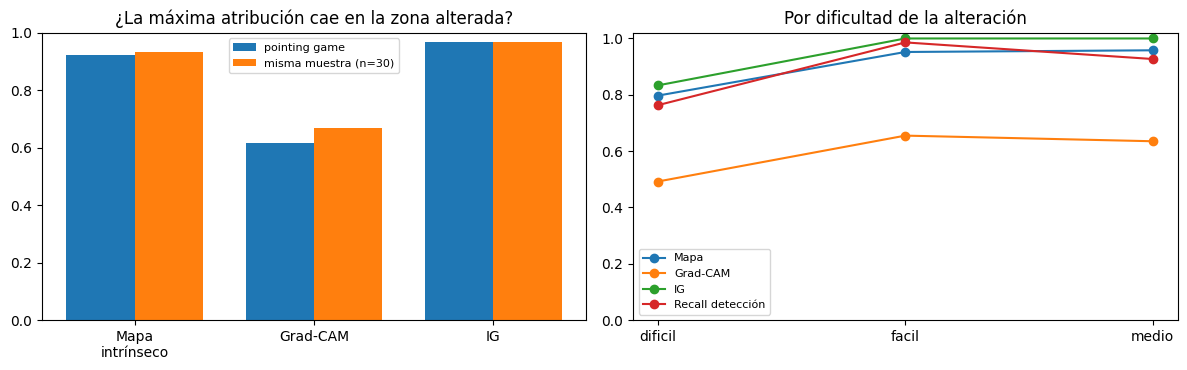

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(3); w = 0.38
ax[0].bar(x - w/2, res["pointing game"], w, label="pointing game")
ax[0].bar(x + w/2, res["pointing en la muestra de IG"], w, label=f"misma muestra (n={len(sub)})")
ax[0].set_xticks(x, ["Mapa\nintrínseco", "Grad-CAM", "IG"]); ax[0].set_ylim(0, 1); ax[0].legend(fontsize=8)
ax[0].set_title("¿La máxima atribución cae en la zona alterada?")
d = by("dificultad")
for k, c in [("pointing_mapa", "Mapa"), ("pointing_gradcam", "Grad-CAM"), ("pointing_ig", "IG"), ("recall", "Recall detección")]:
    ax[1].plot(range(len(d)), d[k], marker="o", label=c)
ax[1].set_xticks(range(len(d)), [s.split("=")[1] for s in d.index]); ax[1].set_ylim(0, 1.02); ax[1].legend(fontsize=8)
ax[1].set_title("Por dificultad de la alteración")
plt.tight_layout(); plt.savefig(OUT / "fig2_global_localizacion.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Búsqueda de atajos, fugas y variables proxy
1. **¿Aprendió *dónde suele estar el total* en vez de *si fue editado*?** Para cada par, se toma el máximo del mapa de sospecha **dentro de la zona alterada** en la alterada y en su gemela auténtica (misma geometría). Si el modelo usara la posición del campo, la gemela también puntuaría alto ahí.
2. **Relleno negro:** el lienzo se rellena con negro hasta múltiplo de 128 → ¿cae la sospecha máxima o la masa de IG en el relleno?
3. **Compresión JPEG como proxy:** las dos gemelas se guardan con calidad JPEG independiente (55-92). ¿La probabilidad de las auténticas correlaciona con el nivel de compresión (media de la tabla de cuantización)?
4. **Falsas alarmas:** ¿dónde dispara el modelo en las auténticas con p ≥ umbral?

In [11]:
def max_in(mp_img, m): return float(mp_img[m].max()) if m.any() else np.nan
loc = []
for pair, d in pair_idx.items():
    ia, iu = d[1], d[0]; m = mask_of(ia)
    sa, su = sus_map(ia), sus_map(iu)
    loc.append({"pair": pair, "sosp_zona_alterada": max_in(sa, m), "sosp_zona_gemela": max_in(su, m),
                "sosp_max_gemela": float(su.max()), "argmax_gemela_en_zona": bool(m.flat[su.argmax()]),
                "prob_alt": df.prob[ia], "prob_aut": df.prob[iu], "campo": recs[ia]["tamper"]["campo"]})
L = pd.DataFrame(loc)
auc_zone = roc_auc_score(np.r_[np.ones(len(L)), np.zeros(len(L))], np.r_[L.sosp_zona_alterada, L.sosp_zona_gemela])
print(f"(1) Sospecha en la zona alterada: alterada mediana={L.sosp_zona_alterada.median():.3f} | gemela auténtica mediana={L.sosp_zona_gemela.median():.3f} | AUC={auc_zone:.3f}")
print(f"    Auténticas cuyo máximo cae en la zona que se alteró en su gemela: {L.argmax_gemela_en_zona.mean():.3%}")
print("    Sospecha media en la zona de la gemela por campo:\n", L.groupby("campo").sosp_zona_gemela.median().round(3).to_dict())

# (2) relleno negro (en coordenadas del lienzo)
def pad_stats(i):
    mp, s = MAPS[i]; img_h, img_w = round(recs_hw[i][0] * s), round(recs_hw[i][1] * s)
    Hc, Wc = mp.shape[0] * 16, mp.shape[1] * 16
    valid = np.zeros_like(mp, bool); valid[: int(np.ceil(img_h / 16)), : int(np.ceil(img_w / 16))] = True
    return not valid.flat[mp.argmax()], 1 - valid.mean()
recs_hw = {i: (df.h[i], df.w[i]) for i in df.i}
pad = pd.DataFrame([dict(zip(["argmax_en_relleno", "frac_relleno"], pad_stats(i)), label=df.label[i]) for i in df.i])
print(f"(2) Máximo del mapa en el relleno negro: {pad.argmax_en_relleno.mean():.3%} de las fotos (el relleno ocupa en promedio {pad.frac_relleno.mean():.1%} del lienzo)")

# (3) compresión JPEG
rho_aut = spearmanr(aut.jpeg_q_tabla, aut.prob).correlation
rho_alt = spearmanr(alt.jpeg_q_tabla, alt.prob).correlation
qd = df.pivot_table(index="pair", columns="label", values="jpeg_q_tabla"); pdiff = df.pivot_table(index="pair", columns="label", values="prob")
rho_pair = spearmanr(qd[1] - qd[0], pdiff[1] - pdiff[0]).correlation
print(f"(3) Spearman(prob, cuantización JPEG): auténticas={rho_aut:.3f} | alteradas={rho_alt:.3f} | diferencia dentro del par={rho_pair:.3f}")

# (4) falsas alarmas
FP = aut[aut.prob >= THRESHOLD]
print(f"(4) Falsas alarmas al umbral {THRESHOLD}: {len(FP)} de {len(aut)}")
short = pd.DataFrame([
    {"prueba": "AUC sospecha en zona (alterada vs gemela)", "valor": round(auc_zone, 3)},
    {"prueba": "Sospecha mediana en zona — alterada", "valor": round(L.sosp_zona_alterada.median(), 3)},
    {"prueba": "Sospecha mediana en zona — gemela auténtica", "valor": round(L.sosp_zona_gemela.median(), 3)},
    {"prueba": "% auténticas con máximo en la zona de su gemela", "valor": round(L.argmax_gemela_en_zona.mean(), 3)},
    {"prueba": "% fotos con máximo del mapa en el relleno", "valor": round(pad.argmax_en_relleno.mean(), 3)},
    {"prueba": "Spearman prob vs compresión (auténticas)", "valor": round(rho_aut, 3)},
    {"prueba": "Spearman prob vs compresión (alteradas)", "valor": round(rho_alt, 3)},
    {"prueba": "Spearman Δprob vs Δcompresión en el par", "valor": round(rho_pair, 3)},
    {"prueba": f"Falsas alarmas @ {THRESHOLD}", "valor": len(FP)},
]); short.to_csv(OUT / "tabla_atajos.csv", index=False); short

(1) Sospecha en la zona alterada: alterada mediana=1.000 | gemela auténtica mediana=0.007 | AUC=0.985
    Auténticas cuyo máximo cae en la zona que se alteró en su gemela: 16.667%
    Sospecha media en la zona de la gemela por campo:
 {'fecha': 0.002, 'item': 0.002, 'iva': 0.01, 'nit_emisor': 0.002, 'nit_receptor': 0.002, 'total': 0.018}
(2) Máximo del mapa en el relleno negro: 0.000% de las fotos (el relleno ocupa en promedio 11.0% del lienzo)
(3) Spearman(prob, cuantización JPEG): auténticas=0.095 | alteradas=0.040 | diferencia dentro del par=-0.010
(4) Falsas alarmas al umbral 0.88: 2 de 300


,prueba,valor
0,AUC sospecha en zona (alterada vs gemela),0.985
1,Sospecha mediana en zona — alterada,1.000
2,Sospecha mediana en zona — gemela auténtica,0.007
3,% auténticas con máximo en la zona de su gemela,0.167
4,% fotos con máximo del mapa en el relleno,0.000
5,Spearman prob vs compresión (auténticas),0.095
6,Spearman prob vs compresión (alteradas),0.040
7,Spearman Δprob vs Δcompresión en el par,-0.010
8,Falsas alarmas @ 0.88,2.000


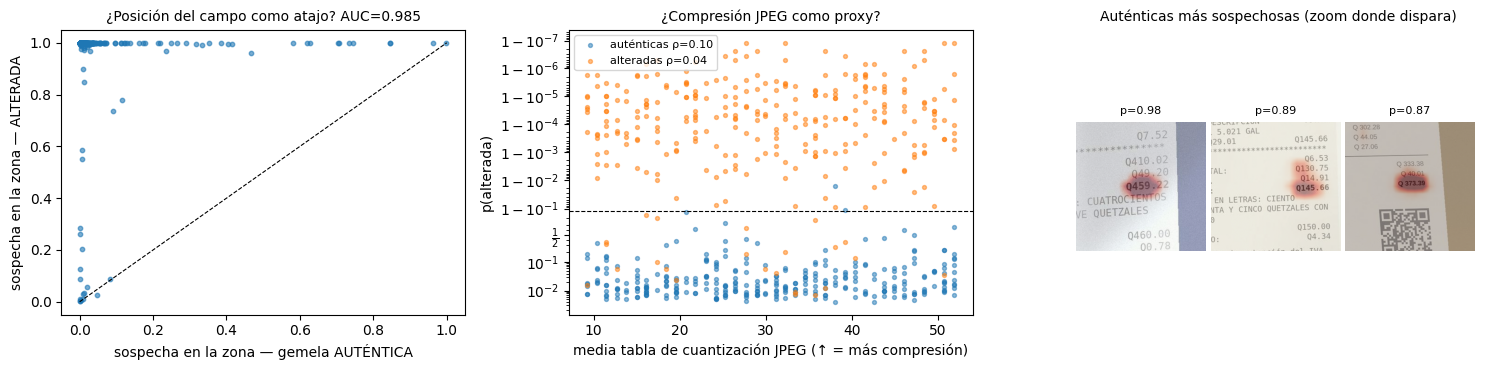

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].scatter(L.sosp_zona_gemela, L.sosp_zona_alterada, s=10, alpha=.6)
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_xlabel("sospecha en la zona — gemela AUTÉNTICA"); ax[0].set_ylabel("sospecha en la zona — ALTERADA")
ax[0].set_title(f"¿Posición del campo como atajo? AUC={auc_zone:.3f}", fontsize=10)
ax[1].scatter(aut.jpeg_q_tabla, aut.prob, s=8, alpha=.5, label=f"auténticas ρ={rho_aut:.2f}")
ax[1].scatter(alt.jpeg_q_tabla, alt.prob, s=8, alpha=.5, label=f"alteradas ρ={rho_alt:.2f}")
ax[1].axhline(THRESHOLD, color="k", ls="--", lw=.8); ax[1].set_yscale("logit"); ax[1].legend(fontsize=8)
ax[1].set_xlabel("media tabla de cuantización JPEG (↑ = más compresión)"); ax[1].set_ylabel("p(alterada)")
ax[1].set_title("¿Compresión JPEG como proxy?", fontsize=10)
# falsas alarmas / auténticas más sospechosas
topfp = aut.sort_values("prob", ascending=False).head(3).i.tolist()
ax[2].axis("off"); ax[2].set_title("Auténticas más sospechosas (zoom donde dispara)", fontsize=10)
for k, i in enumerate(topfp):
    sm = sus_map(i); y0, x0 = zoom_box(i, sm); sl = (slice(y0, y0 + ZOOM), slice(x0, x0 + ZOOM))
    inset = ax[2].inset_axes([k / 3, 0, 0.32, 0.9]); inset.imshow(np.asarray(load(i))[sl])
    inset.imshow(norm01(sm)[sl], cmap="Reds", alpha=.4, vmin=0, vmax=1); inset.axis("off")
    inset.set_title(f"p={df.prob[i]:.2f}", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "fig3_atajos.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Fidelidad: ¿los píxeles señalados *causan* la decisión?
En cada alterada de la muestra, se reemplaza el q % de píxeles más atribuidos por los **píxeles de la gemela auténtica** (un reemplazo dentro de la distribución, a diferencia del negro o el gris) y se mide la caída de p(alterada). Orden aleatorio = piso; reemplazar toda la máscara = techo (oráculo).

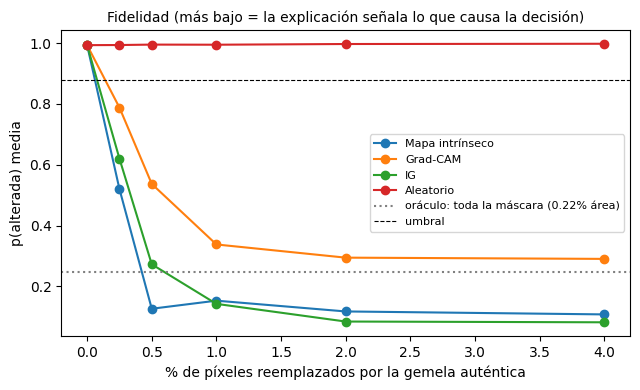

Oráculo (toda la máscara): 0.247


,0%,0.25%,0.5%,1%,2%,4%,% bajo umbral @1%
Mapa intrínseco,0.993,0.520,0.126,0.153,0.118,0.108,0.966667
Grad-CAM,0.993,0.788,0.537,0.338,0.294,0.290,0.800000
IG,0.993,0.620,0.273,0.142,0.084,0.082,0.933333
Aleatorio,0.993,0.994,0.995,0.995,0.997,0.998,0.000000


In [13]:
@torch.no_grad()
def prob_of(arr):
    x, _ = to_x(Image.fromarray(arr)); return torch.sigmoid(model(x)[0]).item()

set_seed()
fid = []
for i in S.i:
    a = np.asarray(load(i)); tw = np.asarray(load(pair_idx[recs[i]["pair"]][0])); m = mask_of(i)
    rnd = np.random.default_rng(SEED + int(i)).random(m.shape)
    maps = {"Mapa intrínseco": sus_map(i), "Grad-CAM": cam_map(i), "IG": ig_map(i)[0], "Aleatorio": rnd}
    row = {"i": i, "p0": df.prob[i]}
    mix = a.copy(); mix[m] = tw[m]; row["oraculo_mascara"] = prob_of(mix); row["area_mascara"] = m.mean()
    for name, sal in maps.items():
        order = np.argsort(-(sal + 1e-9 * rnd).ravel())
        for f in FRACS:
            sel = np.zeros(m.size, bool); sel[order[: int(f * m.size)]] = True; sel = sel.reshape(m.shape)
            mix = a.copy(); mix[sel] = tw[sel]; row[(name, f)] = prob_of(mix)
    fid.append(row)
FID = pd.DataFrame(fid)
plt.figure(figsize=(6.5, 4))
curve = {}
for name in ["Mapa intrínseco", "Grad-CAM", "IG", "Aleatorio"]:
    ys = [FID.p0.mean()] + [FID[(name, f)].mean() for f in FRACS]; curve[name] = ys
    plt.plot([0] + [f * 100 for f in FRACS], ys, marker="o", label=name)
plt.axhline(FID.oraculo_mascara.mean(), color="gray", ls=":", label=f"oráculo: toda la máscara ({FID.area_mascara.median()*100:.2f}% área)")
plt.axhline(THRESHOLD, color="k", ls="--", lw=.8, label="umbral")
plt.xlabel("% de píxeles reemplazados por la gemela auténtica"); plt.ylabel("p(alterada) media"); plt.legend(fontsize=8)
plt.title("Fidelidad (más bajo = la explicación señala lo que causa la decisión)", fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "fig4_fidelidad.png", dpi=150, bbox_inches="tight"); plt.show()
fid_tab = pd.DataFrame(curve, index=["0%"] + [f"{f*100:g}%" for f in FRACS]).T.round(3)
fid_tab["% bajo umbral @1%"] = [ (FID[(n, 0.01)] < THRESHOLD).mean() for n in fid_tab.index ]
fid_tab.to_csv(OUT / "tabla_fidelidad.csv"); print("Oráculo (toda la máscara):", round(FID.oraculo_mascara.mean(), 3)); fid_tab

## 8. *Sanity check* de aleatorización (Adebayo et al., 2018)
Se reinicializa la cabeza `fuse` (la que produce el mapa) y la última etapa del encoder. Si las explicaciones casi no cambian, no dependen de lo aprendido. Se reporta la correlación de Spearman entre mapas original y aleatorizado.

      rho_gradcam  rho_ig
mean        0.098   0.727
std         0.395   0.052


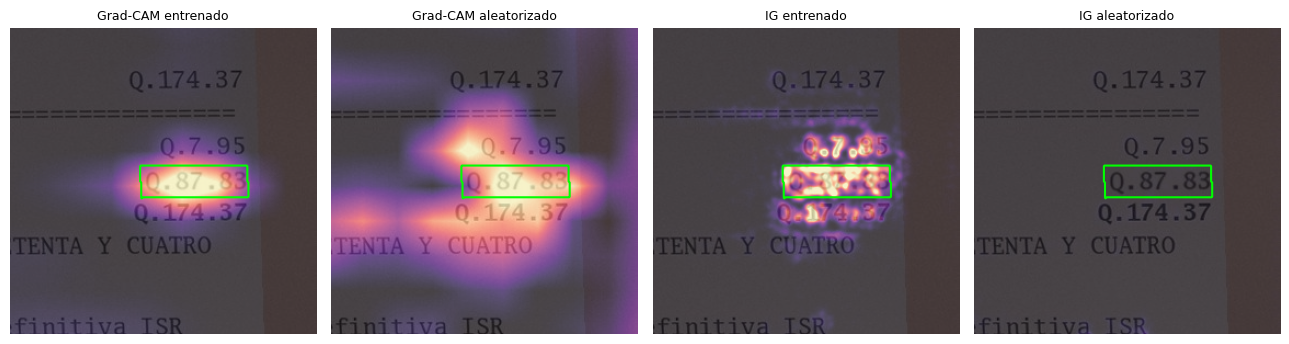

In [14]:
set_seed()
rand = copy.deepcopy(model)
for mod in list(rand.fuse.modules()) + list(rand.enc.blocks[-1].modules()):
    if hasattr(mod, "reset_parameters"): mod.reset_parameters()
rand.eval()
def cam_with(mdl, i): return np.asarray(gradcam(mdl, cfg, load(i)), np.float32) / 255
san = []
for i in S.i[:N_SANITY]:
    sub_ = lambda a: a[::8, ::8].ravel()
    san.append({"i": i,
                "rho_gradcam": spearmanr(sub_(cam_map(i)), sub_(cam_with(rand, i))).correlation,
                "rho_ig": spearmanr(sub_(ig_map(i)[0]), sub_(ig_map(i, rand, cache=False)[0])).correlation})
SAN = pd.DataFrame(san).fillna(0); SAN.to_csv(OUT / "tabla_sanity.csv", index=False)
print(SAN[["rho_gradcam", "rho_ig"]].describe().round(3).loc[["mean", "std"]])
i0 = int(S.i.iloc[0]); m0 = mask_of(i0); y0, x0 = zoom_box(i0, sus_map(i0)); sl = (slice(y0, y0 + ZOOM), slice(x0, x0 + ZOOM))
fig, ax = plt.subplots(1, 4, figsize=(13, 3.4))
for a_, (arr, t) in zip(ax, [(norm01(cam_map(i0)), "Grad-CAM entrenado"), (norm01(cam_with(rand, i0)), "Grad-CAM aleatorizado"),
                            (norm01(ig_map(i0)[0]), "IG entrenado"), (norm01(ig_map(i0, rand, cache=False)[0]), "IG aleatorizado")]):
    a_.imshow(np.asarray(load(i0))[sl]); a_.imshow(arr[sl], cmap="magma", alpha=.7, vmin=0, vmax=1)
    a_.contour(m0[sl], levels=[.5], colors="lime"); a_.set_title(t, fontsize=9); a_.axis("off")
plt.tight_layout(); plt.savefig(OUT / "fig5_sanity.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Costo computacional y parámetros

In [15]:
cost = pd.DataFrame([
    {"método": "Predicción + mapa intrínseco", "pasadas": "1 fwd", "ms/foto": T_FWD * 1e3},
    {"método": "Grad-CAM", "pasadas": "1 fwd + 1 bwd", "ms/foto": T_CAM * 1e3},
    {"método": "Integrated Gradients", "pasadas": f"{IG_STEPS + 2} fwd + {IG_STEPS} bwd", "ms/foto": T_IG * 1e3},
    {"método": "Oclusión 64 px / stride 32 (estimado)", "pasadas": "~800 fwd", "ms/foto": 800 * T_FWD * 1e3},
])
cost["x predicción"] = cost["ms/foto"] / (T_FWD * 1e3); cost = cost.round(1)
cost.to_csv(OUT / "tabla_costo.csv", index=False)
params = {"semilla": SEED, "device": str(DEVICE), "modelo": "models/final/best.pt", "config_modelo": cfg,
          "umbral": THRESHOLD, "test": {"semilla_split": 2028, "pares": len(pair_idx)},
          "ig": {"objetivo": "logit top-k de 'alterada'", "linea_base": f"misma foto con desenfoque gaussiano sigma={BLUR_SIGMA}",
                 "n_steps": IG_STEPS, "metodo": "gausslegendre", "agregacion": "suma de canales, parte positiva",
                 "suavizado_px": SMOOTH_PX, "n_muestra": int(len(S)), "muestreo": "estratificado por dificultad",
                 "error_completitud_relativo_mediana": float(G.ig_rel_delta.median())},
          "gradcam": {"capa": "última etapa del encoder (stride 32)", "implementacion": "src/model.py::gradcam"},
          "fidelidad": {"reemplazo": "píxeles de la gemela auténtica", "fracciones": FRACS},
          "sanity": {"capas_aleatorizadas": ["fuse", "enc.blocks[-1]"], "n": N_SANITY}}
json.dump(params, open(OUT / "parametros_xai.json", "w"), indent=2, ensure_ascii=False, default=str)
print(sorted(p.name for p in OUT.iterdir())); cost

['fig1_locales.png', 'fig2_global_localizacion.png', 'fig3_atajos.png', 'fig4_fidelidad.png', 'fig5_sanity.png', 'parametros_xai.json', 'predicciones.csv', 'tabla_atajos.csv', 'tabla_costo.csv', 'tabla_fidelidad.csv', 'tabla_global_alteradas.csv', 'tabla_locales.csv', 'tabla_localizacion_metodos.csv', 'tabla_sanity.csv', 'tabla_subgrupos.csv']


,método,pasadas,ms/foto,x predicción
0,Predicción + mapa intrínseco,1 fwd,92.6,1.0
1,Grad-CAM,1 fwd + 1 bwd,171.4,1.9
2,Integrated Gradients,34 fwd + 32 bwd,3323.8,35.9
3,Oclusión 64 px / stride 32 (estimado),~800 fwd,74107.8,800.0
